# 01b — The LBNL 2026 data file beside the frozen 2025 file

The project's registered results stand on the 2025 edition of the LBNL queue file (data through 2024, frozen; decision #2). The 2026 edition (data through 2025) is added alongside (decision #43) for two uses: to see how the same requests changed between editions — the file is a snapshot of snapshots, so statuses and even dates move — and to read the 1- and 2-year outcomes of the 2020–2022 entrants, the newest evidence on the level of completion that notebook 12 needs. No model is fitted on this file here.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx` | the frozen 2025 edition (S1) |
| in | `data/raw/lbnl/LBNL_Ix_Queue_Data_File_thru2025.xlsx` | the 2026 edition (S6), SHA-256 checked against `src/config.py` |
| in | `data/interim/queue_clean.parquet`, `data/interim/trackA.parquet` | notebooks 02/04 — the 2025 file cleaned and coded |
| out | `data/interim/queue_clean_2026.parquet`, `results/clean_log_2026.csv` | the 2026 file through rules R2–R9 (R1 is not needed: its dates are real dates) |
| out | `results/lbnl_2026_layout.csv` | column differences between the editions |
| out | `results/lbnl_2026_reconciliation.csv`, `results/lbnl_2026_status_transitions.csv`, `results/lbnl_2026_date_changes.csv` | the same requests in both editions |
| out | `results/lbnl_2026_date_coverage.csv` | event-date coverage by region, both editions |
| out | `results/early_incidence_2020_2022.csv` | P(operation by 1 and 2 years) of the 2020–2022 entrants, both editions |
| out | `docs/data_readiness.md` (section "v3 sources") | the S6 readiness lines, PASS/FAIL |
| out | `figures/01b_lbnl_2026_reconcile/*` | this notebook's figures |
| out | `results/lbnl_2026_checks.csv` | this notebook's checks |

## Setup

In [1]:
import hashlib
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import cleaning, config, drift, events, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "01b_lbnl_2026_reconcile"
TRACK_A = config.TRACK_A_REGIONS
CENSOR_2026 = "2025-12-31"  # end of data collection of the 2026 edition
KEY = ["q_id", "entity", "region"]


def save(fig, name, caption):
    """Save a figure of this notebook under figures/01b_lbnl_2026_reconcile/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Both files, as published

The 2026 file is checked against the SHA-256 recorded in `src/config.py` and loaded from the same sheet and header row as the 2025 file. The column differences are listed, and the 2026 names are mapped back to the 2025 names the pipeline uses (`config.LBNL_2026_RENAMES`).

In [2]:
path_2026 = paths.RAW_LBNL / config.LBNL_2026_FILENAME
digest = hashlib.sha256(path_2026.read_bytes()).hexdigest()
assert digest == config.LBNL_2026_SHA256, "the 2026 file on disk is not the one recorded in src/config.py"

raw_2025 = pd.read_excel(paths.RAW_LBNL / config.LBNL_FILENAME, sheet_name=config.LBNL_SHEET, header=config.LBNL_HEADER_ROW)
raw_2026 = pd.read_excel(path_2026, sheet_name=config.LBNL_SHEET, header=config.LBNL_HEADER_ROW)
layout = pd.DataFrame({
    "column": sorted(set(raw_2025.columns) | set(raw_2026.columns)),
}).assign(in_2025=lambda d: d["column"].isin(raw_2025.columns), in_2026=lambda d: d["column"].isin(raw_2026.columns))
layout["mapped_to"] = layout["column"].map(config.LBNL_2026_RENAMES)
layout.to_csv(paths.RESULTS / "lbnl_2026_layout.csv", index=False)
raw_2026 = raw_2026.rename(columns=config.LBNL_2026_RENAMES)
for column in config.LBNL_DATE_COLS:
    assert pd.api.types.is_datetime64_any_dtype(raw_2026[column]), f"{column} is not a date in the 2026 file"
print(f"2025: {raw_2025.shape}; 2026: {raw_2026.shape}; SHA-256 of the 2026 file verified")
layout[~(layout["in_2025"] & layout["in_2026"])]

2025: (36441, 31); 2026: (38201, 30); SHA-256 of the 2026 file verified


,column,in_2025,in_2026,mapped_to
0,IA_phase_clean,False,True,IA_status_clean
1,IA_phase_raw,False,True,IA_status_raw
2,IA_status_clean,True,False,NaN
3,IA_status_raw,True,False,NaN
6,county_state_pairs,True,False,NaN
9,fips_code,False,True,fips_codes
10,fips_codes,True,False,NaN
12,mw1,True,False,NaN
13,mw2,True,False,NaN
14,mw3,True,False,NaN


**Reading this.** The 2026 edition has 38,201 rows against 36,441, and the same sheet and header row. Nine columns were renamed (the interconnection-agreement status fields are now "phase", the FIPS and the type/MW components carry underscores), `county_state_pairs` is gone, and the five date columns arrive as dates rather than Excel serial numbers, so rule R1 has nothing to do. Nothing in the mapping changes a value.

## 2. Cleaning the 2026 file with the same rules

Rules R2–R9 of notebook 02 run unchanged (`src/cleaning.py`); R1 is skipped because the 2026 file stores real dates, not Excel serials. One step is particular to the 2026 file: it lists 135 operational NYISO and Southeast projects twice, the second copy appended at the end of the sheet without county or operation date, so the emptier copy of each pair is dropped before R7 (which would otherwise refuse the file, as it should for the frozen one). The rule log is written beside notebook 02's so the two can be compared.

In [3]:
log = []
# 2026-only: duplicate (q_id, entity) rows — keep the copy with the most filled fields
with_key = raw_2026.assign(_q=raw_2026["q_id"].astype(str), _filled=raw_2026.notna().sum(axis=1))
with_key = with_key.sort_values("_filled", ascending=False)
dup = with_key.duplicated(["_q", "entity"], keep="first")
dropped = with_key[dup]
log.append({"rule": "R7a", "function": "drop_appended_duplicates_2026", "item": "dropped: emptier copy of a duplicated key",
            "rows": int(dup.sum()), "rows_in": len(raw_2026), "rows_out": int((~dup).sum())})
print(f"appended duplicates dropped: {int(dup.sum())} rows, regions {dropped['region'].value_counts().to_dict()}, "
      f"status {dropped['q_status'].value_counts().to_dict()}")
frame = with_key[~dup].drop(columns=["_q", "_filled"]).sort_index()
for rule in cleaning.RULES[1:]:  # R2 … R9
    frame = cleaning.apply_rule(rule, frame, log)
clean_2026 = frame
for column in clean_2026.columns:
    if clean_2026[column].dtype == object:
        clean_2026[column] = clean_2026[column].astype("string")
clean_2026.to_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")
log_2026 = pd.DataFrame(log)
log_2026.to_csv(paths.RESULTS / "clean_log_2026.csv", index=False)
log_2025 = pd.read_csv(paths.RESULTS / "clean_log.csv")
clean_2025 = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
compare = (log_2025.merge(log_2026, on=["rule", "item"], how="outer", suffixes=("_2025", "_2026"))
           [["rule", "item", "rows_2025", "rows_2026"]])
print(f"clean rows: 2025 {len(clean_2025):,}; 2026 {len(clean_2026):,}")
compare

appended duplicates dropped: 135 rows, regions {'NYISO': 104, 'Southeast': 31}, status {'operational': 135}


clean rows: 2025 36,216; 2026 37,849


,rule,item,rows_2025,rows_2026
0,R1,ia_date converted,2440.0,NaN
1,R1,on_date converted,2957.0,NaN
2,R1,prop_date converted,29029.0,NaN
3,R1,q_date converted,35834.0,NaN
4,R1,wd_date converted,10138.0,NaN
5,R2,ia_date placeholder set to missing,56.0,0.0
6,R2,q_date placeholder set to missing,204.0,0.0
7,R2,q_year changed by recomputing it from q_date,204.0,0.0
8,R3,on_date cleared: before 1950,0.0,0.0
9,R3,on_date cleared: before the request date,69.0,48.0


**Reading this.** The rules touch the two editions in the same places and in similar numbers: a few hundred operation dates cleared because the status is not operational (596 then, 420 now), the same 16 non-positive capacities, the same project-type drops. The 204 placeholder request dates of the 2025 file are gone. One step is new: 135 operational NYISO and Southeast projects appear twice in the 2026 sheet, the second copy without county or operation date, and the emptier copy is dropped. After cleaning: 36,216 rows in 2025, 37,849 in 2026.

## 3. The same requests in both editions

Requests are matched on (`q_id`, `entity`, `region`), the key the codebook names. Three things are counted: the share of 2025 requests found in 2026 (the readiness line asks for 95%), the status each request moved to, and — among requests whose status did not change — whether their recorded dates changed.

In [4]:
def keyed(frame):
    out = frame[KEY + ["q_status", "q_date", "on_date", "wd_date", "ia_date", "mw"]].copy()
    for column in KEY:
        out[column] = out[column].astype("string")
    return out.drop_duplicates(KEY)


a, b = keyed(clean_2025), keyed(clean_2026)
m = a.merge(b, on=KEY, how="left", suffixes=("_2025", "_2026"), indicator=True)
found = m["_merge"] == "both"
recon = (m.groupby("region").agg(requests_2025=("q_status_2025", "size"), found_in_2026=("_merge", lambda s: int((s == "both").sum())))
         .assign(share_found=lambda d: d["found_in_2026"] / d["requests_2025"]))
recon.loc["all"] = [len(m), int(found.sum()), found.mean()]
new_rows = b.merge(a, on=KEY, how="left", indicator=True).query("_merge == 'left_only'")
recon["new_in_2026"] = new_rows.groupby("region").size().reindex(recon.index).fillna(0).astype(int)
recon.loc["all", "new_in_2026"] = len(new_rows)
recon.to_csv(paths.RESULTS / "lbnl_2026_reconciliation.csv")
dup_2026 = int(clean_2026.duplicated(KEY).sum())
print(f"2025 requests found in 2026: {found.mean():.1%}; new 2026 rows: {len(new_rows):,}; duplicate keys in 2026: {dup_2026}")
recon.round(3)

2025 requests found in 2026: 96.9%; new 2026 rows: 2,759; duplicate keys in 2026: 0


,requests_2025,found_in_2026,share_found,new_in_2026
region,,,,
CAISO,2837.0,2698.0,0.951,170
ERCOT,3277.0,3263.0,0.996,489
ISO-NE,1279.0,1279.0,1.000,1
MISO,4929.0,4926.0,0.999,488
NYISO,1816.0,1811.0,0.997,21
PJM,8099.0,7524.0,0.929,89
SPP,2388.0,2388.0,1.000,330
Southeast,3916.0,3798.0,0.970,477
West,7675.0,7403.0,0.965,694


In [5]:
both = m[found]
transitions = pd.crosstab(both["q_status_2025"], both["q_status_2026"])
transitions.to_csv(paths.RESULTS / "lbnl_2026_status_transitions.csv")
moved_back = int(both[(both["q_status_2025"] == "withdrawn") & (both["q_status_2026"] == "operational")].shape[0])
reopened = int(both[(both["q_status_2025"] == "operational") & (both["q_status_2026"] == "active")].shape[0])
active_2024 = both[both["q_status_2025"] == "active"]
print(f"of {len(active_2024):,} requests active at end-2024: "
      + ", ".join(f"{k} {v:,}" for k, v in active_2024["q_status_2026"].value_counts().items()))
print(f"withdrawn → operational: {moved_back}; operational → active: {reopened}")
transitions

of 9,815 requests active at end-2024: active 6,336, withdrawn 2,963, operational 278, suspended 238
withdrawn → operational: 63; operational → active: 80


q_status_2026,active,operational,suspended,unknown,withdrawn
q_status_2025,,,,,
active,6336,278,238,0,2963
operational,80,4222,1,3,16
suspended,60,14,394,0,60
unknown,1,0,0,3,0
withdrawn,39,63,10,0,20309


In [6]:
same = both[both["q_status_2025"] == both["q_status_2026"]]
rows = []
for column in ["q_date", "on_date", "wd_date", "ia_date"]:
    x, y = same[f"{column}_2025"], same[f"{column}_2026"]
    had = x.notna()
    changed = had & y.notna() & (x != y)
    lost = had & y.isna()
    gained = x.isna() & y.notna()
    shift = (y[changed] - x[changed]).dt.days
    rows.append({"date": column, "requests with the date in 2025": int(had.sum()), "changed": int(changed.sum()),
                 "lost in 2026": int(lost.sum()), "gained in 2026": int(gained.sum()),
                 "median shift (days)": float(shift.median()) if changed.any() else np.nan,
                 "share changed": float(changed.sum() / max(had.sum(), 1))})
date_changes = pd.DataFrame(rows)
bulk = same[(same["region"] == "ERCOT") & (same["wd_date_2025"] == pd.Timestamp(config.ERCOT_BULK_WD_DATE))]
date_changes.loc[len(date_changes)] = ["ERCOT wd_date == 2018-08-29 (decision #21)", len(bulk),
                                       int((bulk["wd_date_2026"].notna() & (bulk["wd_date_2026"] != bulk["wd_date_2025"])).sum()),
                                       int(bulk["wd_date_2026"].isna().sum()), 0, np.nan, np.nan]
date_changes.to_csv(paths.RESULTS / "lbnl_2026_date_changes.csv", index=False)
date_changes

,date,requests with the date in 2025,changed,lost in 2026,gained in 2026,median shift (days),share changed
0,q_date,30575,926,1,249,-1.0,0.030286
1,on_date,2166,123,107,865,1.0,0.056787
2,wd_date,9898,54,476,3535,1.5,0.005456
3,ia_date,2152,115,187,2508,863.0,0.053439
4,ERCOT wd_date == 2018-08-29 (decision #21),441,0,441,0,NaN,NaN


**Reading this.** Of the 2025 requests, 96.9% are found in the 2026 file; PJM is the exception at 92.9%, and 2,759 rows are new (ERCOT 489, MISO 488, West 694). The 9,815 requests active at end-2024 went four ways in 2025: 6,336 still active, 2,963 withdrawn, 278 operational, 238 suspended — a 30% withdrawal rate in one year. The file is a snapshot of snapshots: 63 requests went from withdrawn to operational and 80 from operational back to active, which no forward process produces. Among requests whose status did not change, 3% of request dates and 6% of operation dates moved, mostly by a day; 3,535 withdrawal dates and 2,508 interconnection-agreement dates were added; and all 441 ERCOT withdrawals that shared the 2018-08-29 stamp (decision #21) lost their date, which is why ERCOT's withdrawal coverage falls in the next section.

## 4. Event-date coverage by region, both editions

The share of operational rows with an operation date and of withdrawn rows with a withdrawal date — the quantity that decided which regions could carry a timing model (decision #6).

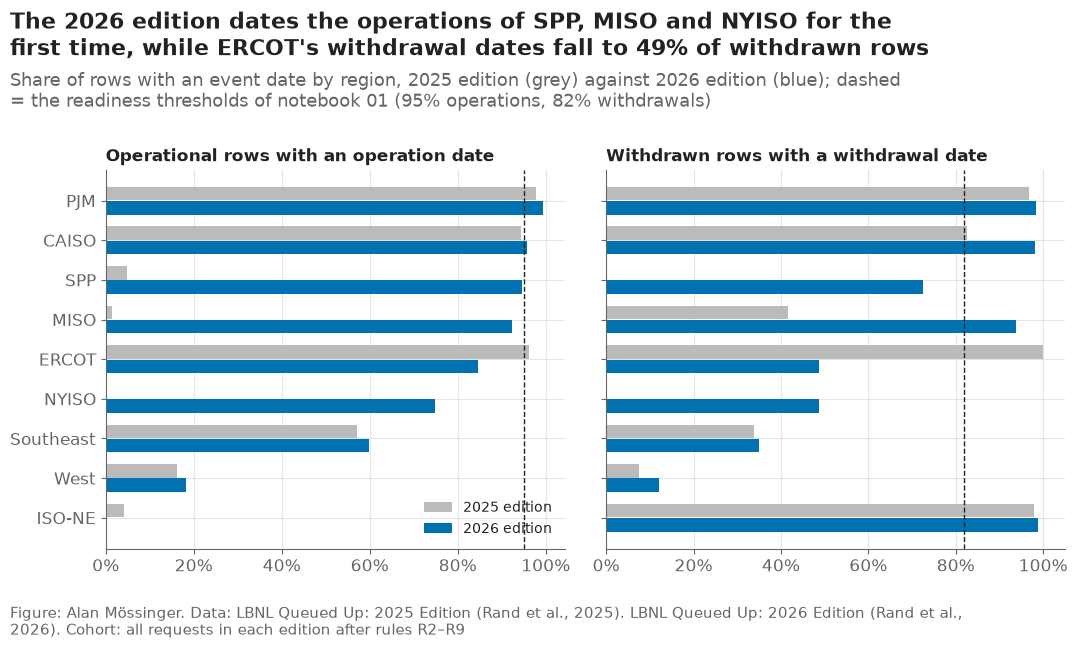

on_date_share        wd_date_share       
edition            2025   2026          2025   2026
region                                             
CAISO             0.943  0.957         0.826  0.982
ERCOT             0.963  0.847         1.000  0.487
ISO-NE            0.041  0.000         0.979  0.988
MISO              0.014  0.924         0.417  0.938
NYISO             0.000  0.748         0.000  0.487
PJM               0.977  0.993         0.969  0.983
SPP               0.049  0.946         0.000  0.726
Southeast         0.572  0.598         0.338  0.349
West              0.161  0.183         0.075  0.121

In [7]:
def coverage(frame, edition):
    op = frame[frame["q_status"] == "operational"].groupby("region")["on_date"].agg(lambda s: s.notna().mean())
    wd = frame[frame["q_status"] == "withdrawn"].groupby("region")["wd_date"].agg(lambda s: s.notna().mean())
    n_op = frame[frame["q_status"] == "operational"].groupby("region").size()
    n_wd = frame[frame["q_status"] == "withdrawn"].groupby("region").size()
    return pd.DataFrame({"edition": edition, "on_date_share": op, "wd_date_share": wd, "n_operational": n_op, "n_withdrawn": n_wd})


cov = pd.concat([coverage(clean_2025, 2025), coverage(clean_2026, 2026)]).reset_index().rename(columns={"index": "region"})
cov.to_csv(paths.RESULTS / "lbnl_2026_date_coverage.csv", index=False)
wide = cov.pivot(index="region", columns="edition", values=["on_date_share", "wd_date_share"])
order = wide.sort_values(("on_date_share", 2026), ascending=False).index

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, what in zip(axes, ["on_date_share", "wd_date_share"]):
    y = np.arange(len(order))
    ax.barh(y - 0.18, wide.loc[order, (what, 2025)], height=0.34, color="#BBBBBB", label="2025 edition")
    ax.barh(y + 0.18, wide.loc[order, (what, 2026)], height=0.34, color="#0072B2", label="2026 edition")
    ax.axvline(config.COVERAGE_MIN_ON_DATE if what == "on_date_share" else config.COVERAGE_MIN_WD_DATE,
               color=plots.INK, linewidth=1, linestyle="--")
    ax.set_yticks(y, order)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_title({"on_date_share": "Operational rows with an operation date",
                  "wd_date_share": "Withdrawn rows with a withdrawal date"}[what], fontsize=12)
axes[0].invert_yaxis()
axes[0].legend(loc="lower right", fontsize=10)
newly = [r for r in order if wide.loc[r, ("on_date_share", 2025)] < 0.10 and wide.loc[r, ("on_date_share", 2026)] >= 0.70]
ercot_wd = wide.loc["ERCOT", ("wd_date_share", 2026)]
plots.finish(fig,
             f"The 2026 edition dates the operations of {', '.join(newly[:-1])} and {newly[-1]} for the first time, "
             f"while ERCOT's withdrawal dates fall to {ercot_wd:.0%} of withdrawn rows",
             "Share of rows with an event date by region, 2025 edition (grey) against 2026 edition (blue); dashed = the "
             "readiness thresholds of notebook 01 (95% operations, 82% withdrawals)",
             "all requests in each edition after rules R2–R9", lbnl_2026=True)
save(fig, "01b_01_date_coverage", "Event-date coverage by region in the 2025 and 2026 editions of the LBNL file.")
plt.show()
wide.round(3)

**Reading this.** The 2026 edition changes which regions can carry a timing model. MISO's operations go from 1% dated to 92% and its withdrawals from 42% to 94%; SPP from 5% to 95% and 0% to 73%; NYISO from nothing to 75% and 49%. ERCOT goes the other way: its withdrawal dates fall from 100% to 49% because the stamped block was removed, and its operation dates from 96% to 85%. PJM and CAISO improve slightly, CAISO's withdrawals from 83% to 98%. So the 2026 file supports MISO and SPP timing models (decision #49, notebook 19) and does not support replacing the 2025 file for ERCOT (decision #48). MISO's 92% is below the 95% threshold notebook 01 set for operations; notebook 19 states that and proceeds.

## 5. The newest evidence on the level: 2020–2022 entrants

The three ISOs' 2020, 2021 and 2022 entrants are coded against each file's own censoring date (2024-12-31 for the 2025 file, 2025-12-31 for the 2026 file) and their Aalen–Johansen P(operation by 1 and 2 years) is computed with bootstrap bands. Notebook 12 compares these with the models' predicted early incidence for the same requests.

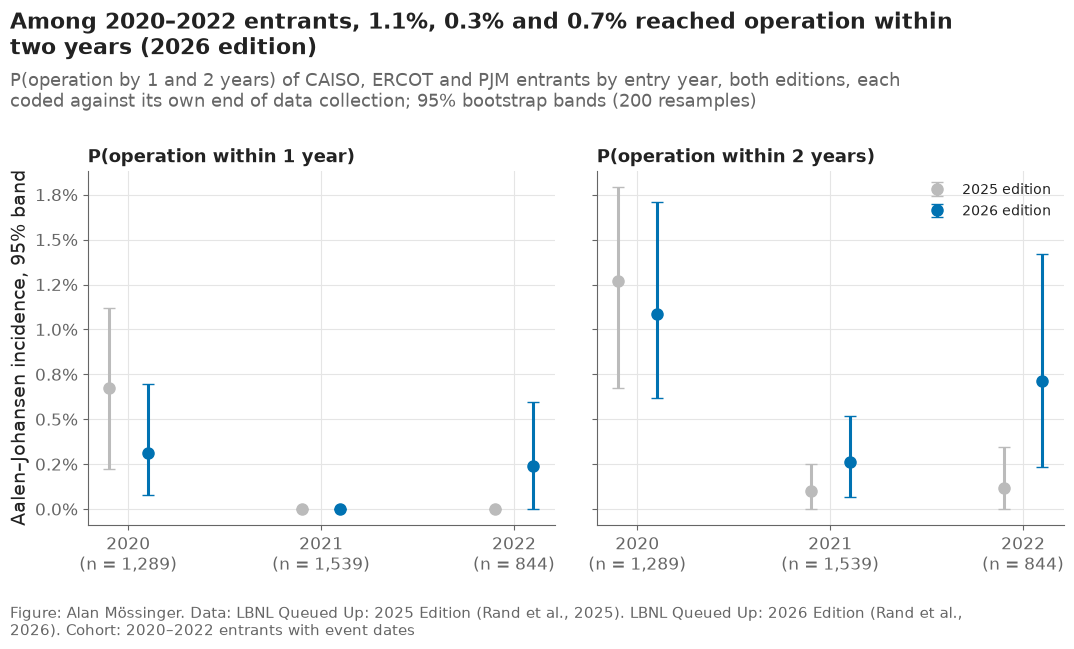

,entry_year,horizon,n,observed,low,high,operations,edition,region
0,2020,1,1340,0.0067,0.0022,0.0112,9,2025,CAISO+ERCOT+PJM
1,2020,2,1340,0.0127,0.0067,0.0179,17,2025,CAISO+ERCOT+PJM
2,2021,1,1973,0.0000,0.0000,0.0000,0,2025,CAISO+ERCOT+PJM
3,2021,2,1973,0.0010,0.0000,0.0025,2,2025,CAISO+ERCOT+PJM
4,2022,1,870,0.0000,0.0000,0.0000,0,2025,CAISO+ERCOT+PJM
5,2022,2,870,0.0011,0.0000,0.0034,1,2025,CAISO+ERCOT+PJM
6,2020,1,1289,0.0031,0.0008,0.0070,4,2026,CAISO+ERCOT+PJM
7,2020,2,1289,0.0109,0.0062,0.0171,14,2026,CAISO+ERCOT+PJM
8,2021,1,1539,0.0000,0.0000,0.0000,0,2026,CAISO+ERCOT+PJM
9,2021,2,1539,0.0026,0.0006,0.0052,4,2026,CAISO+ERCOT+PJM


In [8]:
ev_2026 = events.code_events(clean_2026, censor_date=CENSOR_2026)
ta_2026 = ev_2026[ev_2026["region"].isin(TRACK_A) & (ev_2026["exclusion"] == "")]
ta_2025 = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
YEARS = [2020, 2021, 2022]
early = pd.concat([drift.early_incidence(ta_2025, YEARS, seed=100).assign(edition=2025),
                   drift.early_incidence(ta_2026, YEARS, seed=200).assign(edition=2026)], ignore_index=True)
by_region = pd.concat([drift.early_incidence(ta_2026[ta_2026["region"] == r], YEARS, seed=300).assign(edition=2026, region=r)
                       for r in TRACK_A], ignore_index=True)
early["region"] = "CAISO+ERCOT+PJM"
early = pd.concat([early, by_region], ignore_index=True)
early.to_csv(paths.RESULTS / "early_incidence_2020_2022.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, h in zip(axes, [1, 2]):
    for e_i, (edition, color) in enumerate([(2025, "#BBBBBB"), (2026, "#0072B2")]):
        part = early[(early["edition"] == edition) & (early["horizon"] == h) & (early["region"] == "CAISO+ERCOT+PJM")]
        x = np.arange(len(part)) + (e_i - 0.5) * 0.2
        ax.errorbar(x, part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]], fmt="o",
                    color=color, capsize=4, markersize=8, label=f"{edition} edition")
    ax.set_xticks(range(len(YEARS)), [f"{y}\n(n = {n:,})" for y, n in zip(YEARS, part["n"])])
    ax.set_title(f"P(operation within {h} year{'s' if h > 1 else ''})", fontsize=13)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
axes[0].set_ylabel("Aalen–Johansen incidence, 95% band")
axes[1].legend(loc="upper right", fontsize=10)
e2 = early[(early["edition"] == 2026) & (early["horizon"] == 2) & (early["region"] == "CAISO+ERCOT+PJM")].set_index("entry_year")
plots.finish(fig,
             f"Among 2020–2022 entrants, {e2.loc[2020, 'observed']:.1%}, {e2.loc[2021, 'observed']:.1%} and "
             f"{e2.loc[2022, 'observed']:.1%} reached operation within two years (2026 edition)",
             "P(operation by 1 and 2 years) of CAISO, ERCOT and PJM entrants by entry year, both editions, each coded "
             "against its own end of data collection; 95% bootstrap bands (200 resamples)",
             "2020–2022 entrants with event dates", lbnl_2026=True)
save(fig, "01b_02_early_incidence", "One- and two-year incidence of operation for 2020–2022 entrants in the three ISOs, 2025 and 2026 editions.")
plt.show()
early[early["region"] == "CAISO+ERCOT+PJM"].round(4)

**Reading this.** The newest cohorts have barely started to operate: of the 2020, 2021 and 2022 entrants in the three ISOs, 1.1%, 0.3% and 0.7% reached operation within two years in the 2026 edition, with 14, 4 and 6 operations behind those shares. The two editions agree within their bands. For comparison, 5.3% of the 2017 entrants operated within three years (notebook 08). These early rates are the yardstick notebook 12 holds the models' first- and second-year predictions against; they say nothing yet about five-year completion.

## 6. Readiness lines and checks

The S6 lines of `PLAN.md §5.2`, written into `docs/data_readiness.md` (section "v3 sources") in place of the first-look table.

In [9]:
lines = [
    ("S6 loads and is the stated edition", f"{raw_2026.shape[0]:,} rows × {raw_2026.shape[1]} columns; sheet and header as in 2025; "
     f"{int((~layout['in_2025'] & layout['in_2026']).sum())} columns renamed, {int((layout['in_2025'] & ~layout['in_2026'] & layout['mapped_to'].isna()).sum())} dropped; SHA-256 verified",
     True),
    ("≥ 95% of 2025 requests found in 2026 by (q_id, entity, region)",
     f"{found.mean():.1%} (lowest region {recon.drop('all')['share_found'].idxmin()} {recon.drop('all')['share_found'].min():.1%}); "
     f"{len(new_rows):,} new rows; {dup_2026} duplicate keys", bool(found.mean() >= 0.95)),
    ("status transitions tabulated", f"active at end-2024 → " + ", ".join(f"{k} {v:,}" for k, v in active_2024["q_status_2026"].value_counts().items())
     + f"; withdrawn → operational {moved_back}; operational → active {reopened}", True),
    ("requests whose dates changed listed", "; ".join(f"{r.date}: {r.changed:,} changed, {r['lost in 2026']:,} lost" for _, r in date_changes.iterrows()), True),
    ("2020–2022 early outcomes available", f"{int(early[(early['edition'] == 2026) & (early['region'] == 'CAISO+ERCOT+PJM') & (early['horizon'] == 2)]['n'].sum()):,} entrants in the three ISOs (2026 edition)", True),
    ("the 2025 file is unchanged", "SHA-256 of the frozen file matches src/config.py",
     hashlib.sha256((paths.RAW_LBNL / config.LBNL_FILENAME).read_bytes()).hexdigest() == config.LBNL_SHA256),
]
table = "| Check (PLAN.md §5.2) | Value | Result |\n|---|---|---|\n" + "\n".join(
    f"| {name} | {value} | {'PASS' if ok else 'FAIL'} |" for name, value, ok in lines)
section = ("## v3 sources — S6, the LBNL 2026 data file (notebook 01b)\n\n"
           f"Written by `notebooks/01b_lbnl_2026_reconcile.ipynb`. File `{config.LBNL_2026_FILENAME}`, "
           f"SHA-256 `{config.LBNL_2026_SHA256[:8]}…{config.LBNL_2026_SHA256[-5:]}`.\n\n" + table + "\n\n"
           "Event-date coverage by region in both editions: `results/lbnl_2026_date_coverage.csv` (figure 01b_01). "
           "The 2025 file stays the basis of every registered result (decisions #43, #48).\n")
readiness = paths.DOCS / "data_readiness.md"
text = readiness.read_text(encoding="utf-8")
head = text.split("\n## v3 sources")[0].rstrip("\n")
readiness.write_text(head + "\n\n" + section, encoding="utf-8")

checks = pd.DataFrame([{"check": name, "value": value, "pass": ok} for name, value, ok in lines])
checks.to_csv(paths.RESULTS / "lbnl_2026_checks.csv", index=False)
assert checks["pass"].all(), checks
checks[["check", "pass"]]

,check,pass
0,S6 loads and is the stated edition,True
1,"≥ 95% of 2025 requests found in 2026 by (q_id,...",True
2,status transitions tabulated,True
3,requests whose dates changed listed,True
4,2020–2022 early outcomes available,True
5,the 2025 file is unchanged,True


## Takeaways

- The 2026 edition (38,201 rows, data through 2025) loads with nine renamed columns and real dates; 96.9% of the 2025 requests are found in it, 2,759 rows are new, and 135 appended duplicates are dropped.
- Of 9,815 requests active at end-2024, 2,963 withdrew, 278 reached operation and 238 were suspended during 2025; 63 withdrawn requests reappear as operational and 80 operational ones as active — the file is a snapshot of snapshots.
- MISO, SPP and NYISO operations are dated for the first time (92%, 95%, 75%); ERCOT's withdrawal dates fall to 49% because the 441 stamped withdrawals lost their date.
- 2020–2022 entrants: 1.1%, 0.3% and 0.7% operated within two years (2026 edition); the yardstick for notebook 12.
- **What goes to the report:** the data section (two editions, why both), figure 01b_01, the status-transition table as the "snapshot of snapshots" evidence, and the early-incidence table for the level repair.